In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("spam.csv", encoding="latin-1")

In [5]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (5572, 5)

Column names:
['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


In [6]:

print("\nFirst 5 rows:")
display(df.head())


First 5 rows:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [7]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [8]:
print(df[["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]].isnull().sum())

print("\nTotal rows:", len(df))

print("\nNon-missing values:")
print(df[["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]].notnull().sum())

Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Total rows: 5572

Non-missing values:
Unnamed: 2    50
Unnamed: 3    12
Unnamed: 4     6
dtype: int64


In [9]:
extra_columns = ["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]

for column in extra_columns:
    print(f"\nColumn: {column}")
    print(df.loc[df[column].notna(), ["v1", "v2", column]].head(10))


Column: Unnamed: 2
        v1                                                 v2  \
95    spam  Your free ringtone is waiting to be collected....   
281    ham                                \Wen u miss someone   
444    ham  \HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAR...   
671   spam         SMS. ac sun0819 posts HELLO:\You seem cool   
710    ham  Height of Confidence: All the Aeronautics prof...   
899   spam  Your free ringtone is waiting to be collected....   
1038   ham  Edison has rightly said, \A fool can ask more ...   
1127   ham  Height of \Oh shit....!!\" situation: A guy th...   
1266   ham    \Hey sorry I didntgive ya a a bellearlier hunny   
1384   ham  Storming msg: Wen u lift d phne, u say \HELLO\...   

                                             Unnamed: 2  
95                                          PO Box 5249  
281    the person is definitely special for u..... B...  
444    HOWU DOIN? FOUNDURSELF A JOBYET SAUSAGE?LOVE ...  
671    wanted to say hi. HI!!!\"

In [10]:
extra_columns = ["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]

for column in extra_columns:
    df["v2"] = (
        df["v2"].fillna("").astype(str)
        + " "
        + df[column].fillna("").astype(str)
    ).str.strip()

df = df.drop(columns=extra_columns)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (5572, 2)
     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


v1
ham     4825
spam     747
Name: count, dtype: int64


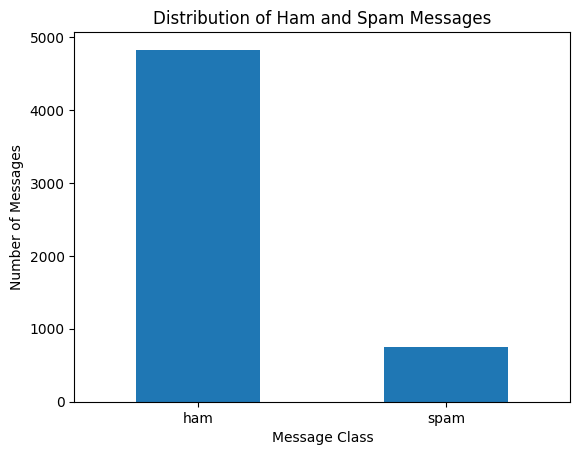

In [11]:
import matplotlib.pyplot as plt

class_counts = df["v1"].value_counts()

print(class_counts)

class_counts.plot(kind="bar")
plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Class")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X = df["v2"].fillna("")
y = df["v1"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", len(X_train))
print("Validation set:", len(X_val))
print("Testing set:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))

Training set: 3343
Validation set: 1114
Testing set: 1115
Total: 5572


In [13]:
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name} class distribution:")
    print(labels.value_counts())
    print((labels.value_counts(normalize=True) * 100).round(2))


Training class distribution:
v1
ham     2895
spam     448
Name: count, dtype: int64
v1
ham     86.6
spam    13.4
Name: proportion, dtype: float64

Validation class distribution:
v1
ham     965
spam    149
Name: count, dtype: int64
v1
ham     86.62
spam    13.38
Name: proportion, dtype: float64

Testing class distribution:
v1
ham     965
spam    150
Name: count, dtype: int64
v1
ham     86.55
spam    13.45
Name: proportion, dtype: float64


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=1000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training:", X_train_tfidf.shape)
print("Validation:", X_val_tfidf.shape)
print("Testing:", X_test_tfidf.shape)

Training: (3343, 1000)
Validation: (1114, 1000)
Testing: (1115, 1000)


In [15]:

from scipy.optimize import minimize

class ManualSVM:
    def __init__(self, C=1.0, max_iter=2000):
        self.C = C
        self.max_iter = max_iter
        self.w = None
        self.b = 0.0
        self.loss_history = []

    def objective(self, params, X, y):
        n_features = X.shape[1]

        w = params[:n_features]
        b = params[n_features]

        scores = np.asarray(X @ w).ravel() + b
        margins = y * scores
        hinge = np.maximum(0, 1 - margins)

        loss = 0.5 * np.dot(w, w) + self.C * np.sum(hinge ** 2)

        active = margins < 1

        grad_w = w.copy()
        grad_b = 0.0

        if np.any(active):
            weighted_labels = y[active] * hinge[active]

            grad_w -= 2 * self.C * np.asarray(
                X[active].T @ weighted_labels
            ).ravel()

            grad_b -= 2 * self.C * np.sum(weighted_labels)

        gradient = np.append(grad_w, grad_b)

        return loss, gradient

    def fit(self, X, y):
        n_features = X.shape[1]
        initial_params = np.zeros(n_features + 1)

        result = minimize(
            self.objective,
            initial_params,
            args=(X, y),
            method="L-BFGS-B",
            jac=True,
            options={"maxiter": self.max_iter}
        )

        self.w = result.x[:n_features]
        self.b = result.x[n_features]
        self.final_loss = result.fun
        self.optimization_success = result.success
        self.optimization_message = result.message

        return self

    def decision_function(self, X):
        return np.asarray(X @ self.w).ravel() + self.b

    def predict(self, X):
        scores = self.decision_function(X)
        return np.where(scores >= 0, 1, -1)

In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_train_svm = np.where(y_train.to_numpy() == "spam", 1, -1)
y_val_svm = np.where(y_val.to_numpy() == "spam", 1, -1)

C_values = [0.1, 1, 10, 100]

results = []
trained_models = {}

for C_value in C_values:
    model = ManualSVM(C=C_value, max_iter=2000)
    model.fit(X_train_tfidf, y_train_svm)

    y_val_pred = model.predict(X_val_tfidf)

    results.append({
        "C": C_value,
        "Validation Accuracy": accuracy_score(y_val_svm, y_val_pred),
        "Spam Precision": precision_score(
            y_val_svm, y_val_pred, pos_label=1, zero_division=0
        ),
        "Spam Recall": recall_score(
            y_val_svm, y_val_pred, pos_label=1, zero_division=0
        ),
        "Spam F1-Score": f1_score(
            y_val_svm, y_val_pred, pos_label=1, zero_division=0
        ),
        "Training Objective Loss": model.final_loss,
        "Optimizer Converged": model.optimization_success
    })

    trained_models[C_value] = model

evaluation_table = pd.DataFrame(results)

evaluation_table = evaluation_table.sort_values(
    by="Spam F1-Score",
    ascending=False
).reset_index(drop=True)

print(evaluation_table.round(4).to_string(index=False))

best_C = evaluation_table.loc[0, "C"]
best_model = trained_models[best_C]

print("\nBest C:", best_C)
print(
    "Best validation Spam F1-score:",
    round(evaluation_table.loc[0, "Spam F1-Score"], 4)
)

    C  Validation Accuracy  Spam Precision  Spam Recall  Spam F1-Score  Training Objective Loss  Optimizer Converged
 10.0               0.9803          0.9379       0.9128         0.9252                 337.0232                 True
  1.0               0.9785          0.9562       0.8792         0.9161                 154.3515                 True
100.0               0.9713          0.8980       0.8859         0.8919                 767.0556                 True
  0.1               0.9731          0.9760       0.8188         0.8905                  50.5495                 True

Best C: 10.0
Best validation Spam F1-score: 0.9252


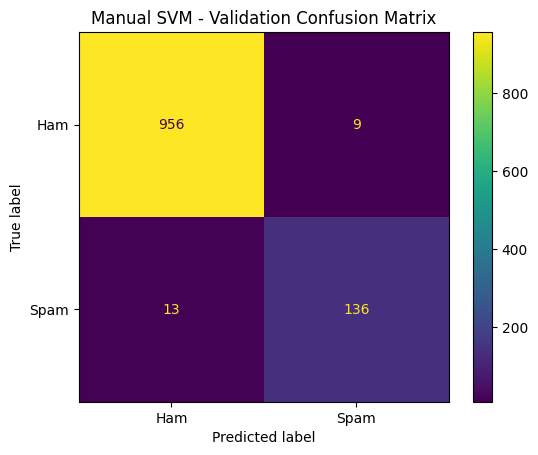

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


y_val_svm = np.where(y_val.to_numpy() == "spam", 1, -1)
y_val_pred = best_model.predict(X_val_tfidf)

cm = confusion_matrix(y_val_svm, y_val_pred, labels=[-1, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot(values_format="d")
plt.title("Manual SVM - Validation Confusion Matrix")
plt.show()

In [ ]:


y_val_actual = np.where(y_val.to_numpy() == "spam", 1, -1)
y_val_pred = best_model.predict(X_val_tfidf)

error_analysis = pd.DataFrame({
    "Message": X_val.to_numpy(),
    "Actual": np.where(y_val_actual == 1, "spam", "ham"),
    "Predicted": np.where(y_val_pred == 1, "spam", "ham"),
    "Decision_Score": best_model.decision_function(X_val_tfidf)
})

false_positives = error_analysis[
    (error_analysis["Actual"] == "ham") &
    (error_analysis["Predicted"] == "spam")
].copy()

false_negatives = error_analysis[
    (error_analysis["Actual"] == "spam") &
    (error_analysis["Predicted"] == "ham")
].copy()

print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))

False Positives: 9
False Negatives: 13


In [19]:
false_positives["Error_Type"] = "False Positive"
false_negatives["Error_Type"] = "False Negative"

mistakes = pd.concat(
    [false_positives, false_negatives],
    ignore_index=True
)

mistakes["Absolute_Score"] = mistakes["Decision_Score"].abs()

mistakes["Confidence_Group"] = pd.cut(
    mistakes["Absolute_Score"],
    bins=[-0.001, 0.5, 1.0, float("inf")],
    labels=["Near Boundary", "Moderate", "Far from Boundary"]
)

print(mistakes.groupby(
    ["Error_Type", "Confidence_Group"],
    observed=False
).size().unstack(fill_value=0))

Confidence_Group  Near Boundary  Moderate  Far from Boundary
Error_Type                                                  
False Negative                2         5                  6
False Positive                4         3                  2


In [20]:
import re
from collections import Counter

def get_common_words(messages):
    words = []

    for message in messages:
        words.extend(
            re.findall(r"\b[a-zA-Z]{2,}\b", message.lower())
        )

    return Counter(words).most_common(15)

print("Common words in False Positives:")
print(get_common_words(false_positives["Message"]))

print("\nCommon words in False Negatives:")
print(get_common_words(false_negatives["Message"]))

Common words in False Positives:
[('to', 7), ('the', 4), ('for', 4), ('new', 2), ('not', 2), ('text', 2), ('or', 2), ('these', 2), ('have', 2), ('on', 2), ('as', 2), ('sms', 2), ('liked', 1), ('mobile', 1), ('urgh', 1)]

Common words in False Negatives:
[('you', 6), ('to', 5), ('on', 5), ('are', 4), ('have', 4), ('for', 3), ('they', 3), ('msg', 3), ('the', 3), ('so', 2), ('email', 2), ('call', 2), ('back', 2), ('over', 2), ('me', 2)]


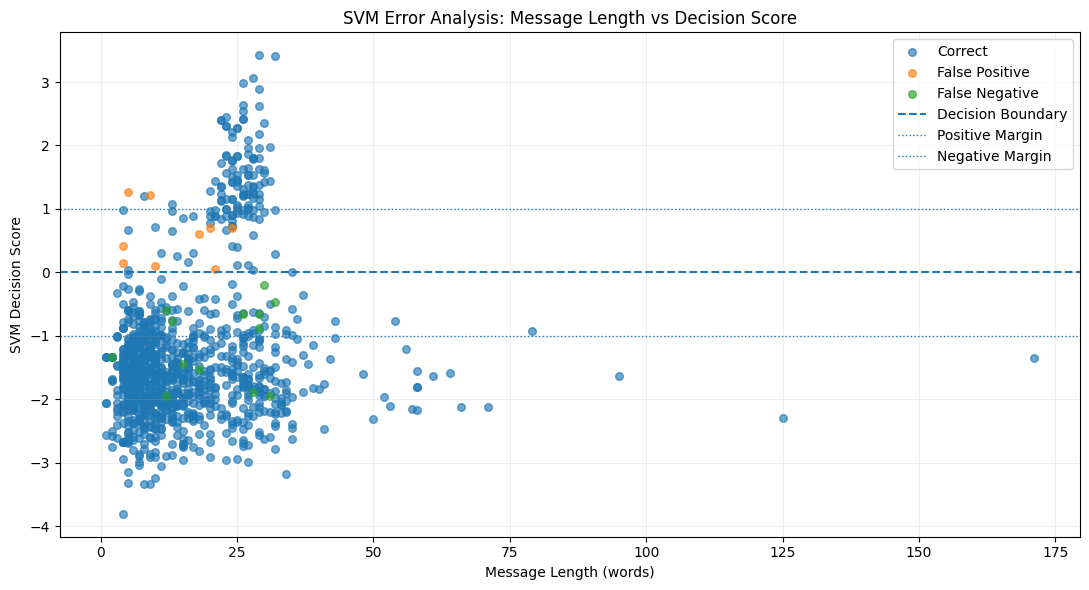

In [ ]:


actual = np.where(y_val.to_numpy() == "spam", 1, -1)
predicted = best_model.predict(X_val_tfidf)
scores = best_model.decision_function(X_val_tfidf)

results = pd.DataFrame({
    "Message_Length": [len(str(msg).split()) for msg in X_val],
    "Actual": actual,
    "Predicted": predicted,
    "Decision_Score": scores
})

results["Error_Type"] = "Correct"
results.loc[
    (results["Actual"] == -1) & (results["Predicted"] == 1),
    "Error_Type"
] = "False Positive"

results.loc[
    (results["Actual"] == 1) & (results["Predicted"] == -1),
    "Error_Type"
] = "False Negative"

plt.figure(figsize=(11, 6))

for category in ["Correct", "False Positive", "False Negative"]:
    subset = results[results["Error_Type"] == category]

    plt.scatter(
        subset["Message_Length"],
        subset["Decision_Score"],
        label=category,
        alpha=0.65,
        s=30
    )

plt.axhline(0, linestyle="--", linewidth=1.5, label="Decision Boundary")
plt.axhline(1, linestyle=":", linewidth=1, label="Positive Margin")
plt.axhline(-1, linestyle=":", linewidth=1, label="Negative Margin")

plt.xlabel("Message Length (words)")
plt.ylabel("SVM Decision Score")
plt.title("SVM Error Analysis: Message Length vs Decision Score")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [22]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

sigmoid_svm = SVC(kernel="sigmoid")

param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    estimator=sigmoid_svm,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_tfidf, y_train_svm)

best_sigmoid_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

y_val_pred_sigmoid = best_sigmoid_model.predict(X_val_tfidf)

print("Validation Accuracy:",
      accuracy_score(y_val_svm, y_val_pred_sigmoid))

print(classification_report(
    y_val_svm,
    y_val_pred_sigmoid,
    labels=[-1, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'C': 10, 'gamma': 0.1}
Best Cross-Validation Accuracy: 0.9853423198446156
Validation Accuracy: 0.9766606822262118
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       965
        Spam       0.95      0.87      0.91       149

    accuracy                           0.98      1114
   macro avg       0.96      0.93      0.95      1114
weighted avg       0.98      0.98      0.98      1114



In [23]:
import numpy as np

y_train_svm = np.where(np.asarray(y_train) == "spam", 1, -1)
y_val_svm = np.where(np.asarray(y_val) == "spam", 1, -1)
y_test_svm = np.where(np.asarray(y_test) == "spam", 1, -1)

print("Training labels:", np.unique(y_train_svm, return_counts=True))
print("Validation labels:", np.unique(y_val_svm, return_counts=True))
print("Test labels:", np.unique(y_test_svm, return_counts=True))

print("TF-IDF training samples:", X_train_tfidf.shape[0])
print("Training label count:", len(y_train_svm))

Training labels: (array([-1,  1]), array([2895,  448]))
Validation labels: (array([-1,  1]), array([965, 149]))
Test labels: (array([-1,  1]), array([965, 150]))
TF-IDF training samples: 3343
Training label count: 3343


In [ ]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

best_C = evaluation_table.loc[
    evaluation_table["Spam F1-Score"].idxmax(), "C"
]
manual_best_model = trained_models[best_C]



manual_predictions = manual_best_model.predict(X_val_tfidf)
sigmoid_predictions = best_sigmoid_model.predict(X_val_tfidf)
comparison_results = []

models = {
    "Manual Linear SVM (L-BFGS-B)": manual_predictions,
    "Sigmoid Kernel SVM (GridSearchCV)": sigmoid_predictions
}

for model_name, predictions in models.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val_svm, predictions),
        "Spam Precision": precision_score(
            y_val_svm, predictions, pos_label=1, zero_division=0
        ),
        "Spam Recall": recall_score(
            y_val_svm, predictions, pos_label=1, zero_division=0
        ),
        "Spam F1-Score": f1_score(
            y_val_svm, predictions, pos_label=1, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print("Best Manual SVM C:", best_C)
print("\nModel Performance Comparison:")
print(comparison_df.round(4).to_string(index=False))

# Compare confusion matrices
for model_name, predictions in models.items():
    print(f"\n{model_name} - Confusion Matrix")
    print(confusion_matrix(y_val_svm, predictions, labels=[-1, 1]))


Best Manual SVM C: 10.0

Model Performance Comparison:
                            Model  Accuracy  Spam Precision  Spam Recall  Spam F1-Score
     Manual Linear SVM (L-BFGS-B)    0.9803          0.9379       0.9128         0.9252
Sigmoid Kernel SVM (GridSearchCV)    0.9767          0.9489       0.8725         0.9091

Manual Linear SVM (L-BFGS-B) - Confusion Matrix
[[956   9]
 [ 13 136]]

Sigmoid Kernel SVM (GridSearchCV) - Confusion Matrix
[[958   7]
 [ 19 130]]



Manual Linear SVM
True Negatives (Ham correctly identified): 956
False Positives (Ham wrongly marked spam): 9
False Negatives (Spam wrongly marked ham): 13
True Positives (Spam correctly identified): 136
Accuracy: 0.9803
Spam Precision: 0.9379
Spam Recall: 0.9128
Spam F1-score: 0.9252


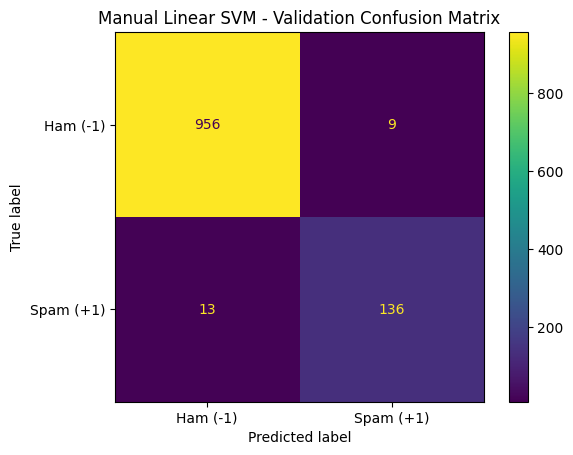


Sigmoid Kernel SVM
True Negatives (Ham correctly identified): 958
False Positives (Ham wrongly marked spam): 7
False Negatives (Spam wrongly marked ham): 19
True Positives (Spam correctly identified): 130
Accuracy: 0.9767
Spam Precision: 0.9489
Spam Recall: 0.8725
Spam F1-score: 0.9091


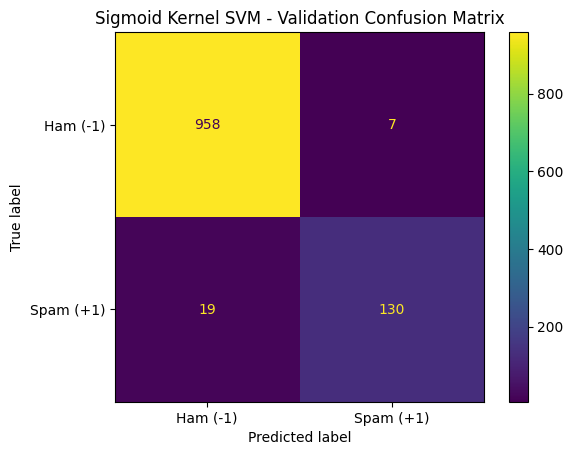

In [25]:


manual_predictions = manual_best_model.predict(X_val_tfidf)
sigmoid_predictions = best_sigmoid_model.predict(X_val_tfidf)

models = {
    "Manual Linear SVM": manual_predictions,
    "Sigmoid Kernel SVM": sigmoid_predictions
}

for model_name, predictions in models.items():
    cm = confusion_matrix(
        y_val_svm,
        predictions,
        labels=[-1, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    print(f"\n{model_name}")
    print("True Negatives (Ham correctly identified):", tn)
    print("False Positives (Ham wrongly marked spam):", fp)
    print("False Negatives (Spam wrongly marked ham):", fn)
    print("True Positives (Spam correctly identified):", tp)

    print("Accuracy:", round(accuracy_score(y_val_svm, predictions), 4))
    print("Spam Precision:", round(
        precision_score(y_val_svm, predictions, pos_label=1,
                        zero_division=0), 4))
    print("Spam Recall:", round(
        recall_score(y_val_svm, predictions, pos_label=1,
                    zero_division=0), 4))
    print("Spam F1-score:", round(
        f1_score(y_val_svm, predictions, pos_label=1,
                 zero_division=0), 4))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Ham (-1)", "Spam (+1)"]
    )

    display.plot(values_format="d")
    plt.title(f"{model_name} - Validation Confusion Matrix")
    plt.show()


In [ ]:

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=SVC(kernel="rbf"),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

grid_search.fit(X_train_tfidf, y_train_svm)

rbf_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best Mean CV Spam F1-Score:", grid_search.best_score_)

y_val_pred = rbf_model.predict(X_val_tfidf)

print("Validation Accuracy:", accuracy_score(y_val_svm, y_val_pred))
print("Spam Precision:", precision_score(y_val_svm, y_val_pred, pos_label=1, zero_division=0))
print("Spam Recall:", recall_score(y_val_svm, y_val_pred, pos_label=1, zero_division=0))
print("Spam F1-Score:", f1_score(y_val_svm, y_val_pred, pos_label=1, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_svm, y_val_pred, labels=[-1, 1]))

print("\nClassification Report:")
print(classification_report(
    y_val_svm,
    y_val_pred,
    labels=[-1, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'C': 10, 'gamma': 0.1}
Best Mean CV Spam F1-Score: 0.9371951521497655
Validation Accuracy: 0.9784560143626571
Spam Precision: 0.9496402877697842
Spam Recall: 0.8859060402684564
Spam F1-Score: 0.9166666666666666

Confusion Matrix:
[[958   7]
 [ 17 132]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       965
        Spam       0.95      0.89      0.92       149

    accuracy                           0.98      1114
   macro avg       0.97      0.94      0.95      1114
weighted avg       0.98      0.98      0.98      1114



In [40]:

y_val_pred = rbf_model.predict(X_val_tfidf)

print("Validation Accuracy:", accuracy_score(y_val_svm, y_val_pred))
print("Spam Precision:", precision_score(y_val_svm, y_val_pred, pos_label=1, zero_division=0))
print("Spam Recall:", recall_score(y_val_svm, y_val_pred, pos_label=1, zero_division=0))
print("Spam F1-Score:", f1_score(y_val_svm, y_val_pred, pos_label=1, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_svm, y_val_pred, labels=[-1, 1]))

print("\nClassification Report:")
print(
    classification_report(
        y_val_svm,
        y_val_pred,
        labels=[-1, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)


Validation Accuracy: 0.9784560143626571
Spam Precision: 0.9496402877697842
Spam Recall: 0.8859060402684564
Spam F1-Score: 0.9166666666666666

Confusion Matrix:
[[958   7]
 [ 17 132]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       965
        Spam       0.95      0.89      0.92       149

    accuracy                           0.98      1114
   macro avg       0.97      0.94      0.95      1114
weighted avg       0.98      0.98      0.98      1114



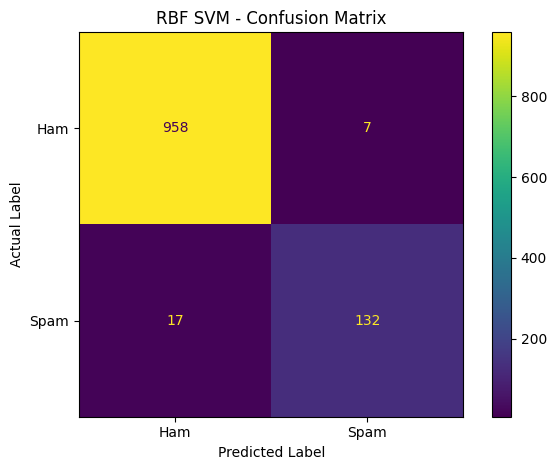

In [42]:


cm = confusion_matrix(
    y_val_svm,
    y_val_pred,
    labels=[-1, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display.plot(values_format="d")
plt.title("RBF SVM - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


In [55]:


models = {
    "Manual Linear SVM": best_model,
    "RBF SVM": rbf_model
}

results = []

for model_name, model in models.items():
    y_pred = model.predict(X_val_tfidf)

    results.append({
        "Model": model_name,
        "Best Parameters": (
            f"C={best_C}"
            if model_name == "Manual Linear SVM"
            else str(grid_search.best_params_)
        ),
        "Validation Accuracy": accuracy_score(y_val_svm, y_pred),
        "Spam Precision": precision_score(
            y_val_svm, y_pred, pos_label=1, zero_division=0
        ),
        "Spam Recall": recall_score(
            y_val_svm, y_pred, pos_label=1, zero_division=0
        ),
        "Spam F1-Score": f1_score(
            y_val_svm, y_pred, pos_label=1, zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)
print(comparison_df.round(4).to_string(index=False))

            Model         Best Parameters  Validation Accuracy  Spam Precision  Spam Recall  Spam F1-Score
Manual Linear SVM                  C=10.0               0.9803          0.9379       0.9128         0.9252
          RBF SVM {'C': 10, 'gamma': 0.1}               0.9785          0.9496       0.8859         0.9167


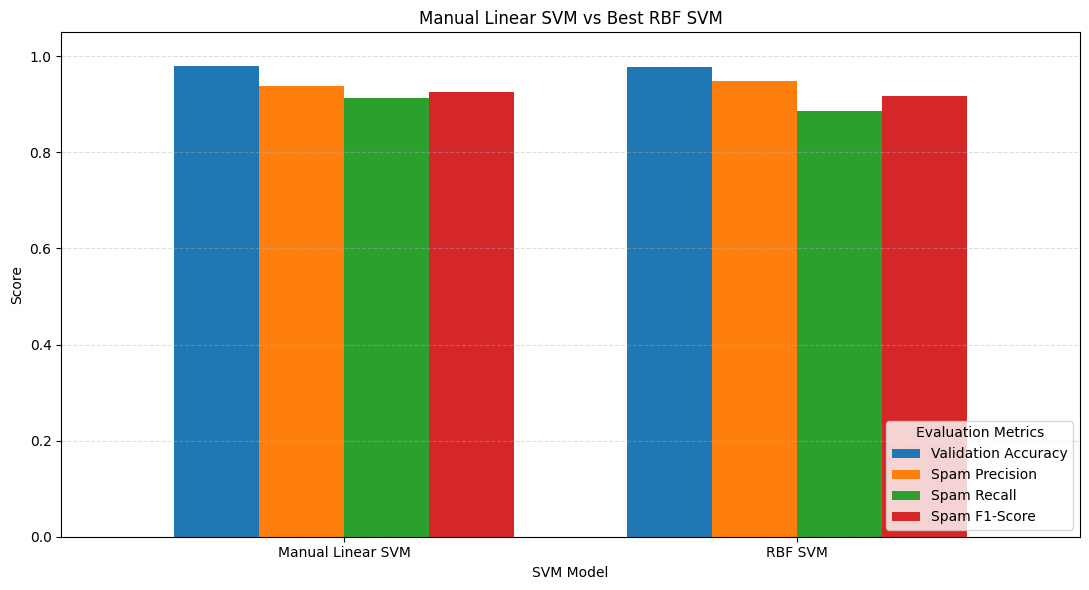

In [47]:

metrics = [
    "Validation Accuracy",
    "Spam Precision",
    "Spam Recall",
    "Spam F1-Score"
]

ax = comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Manual Linear SVM vs Best RBF SVM")
ax.set_ylabel("Score")
ax.set_xlabel("SVM Model")
ax.set_ylim(0, 1.05)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Evaluation Metrics", loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [49]:
test_models = {
    "Manual Linear SVM": best_model,
    "Best RBF SVM": rbf_model
}

test_results = []

for model_name, model in test_models.items():
    y_test_pred = model.predict(X_test_tfidf)

    test_results.append({
        "Model": model_name,
        "Test Accuracy": accuracy_score(y_test_svm, y_test_pred),
        "Spam Precision": precision_score(
            y_test_svm, y_test_pred, pos_label=1, zero_division=0
        ),
        "Spam Recall": recall_score(
            y_test_svm, y_test_pred, pos_label=1, zero_division=0
        ),
        "Spam F1-Score": f1_score(
            y_test_svm, y_test_pred, pos_label=1, zero_division=0
        )
    })

    print(f"\n{'=' * 50}")
    print(model_name)
    print("=" * 50)

    print("\nConfusion Matrix:")
    print(confusion_matrix(
        y_test_svm, y_test_pred, labels=[-1, 1]
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_test_svm,
        y_test_pred,
        labels=[-1, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    ))

test_comparison_df = pd.DataFrame(test_results)

print("\nFinal Held-Out Test Comparison:")
print(test_comparison_df.round(4).to_string(index=False))


Manual Linear SVM

Confusion Matrix:
[[962   3]
 [ 13 137]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       965
        Spam       0.98      0.91      0.94       150

    accuracy                           0.99      1115
   macro avg       0.98      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115


Best RBF SVM

Confusion Matrix:
[[964   1]
 [ 11 139]]

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       965
        Spam       0.99      0.93      0.96       150

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.98      1115
weighted avg       0.99      0.99      0.99      1115


Final Held-Out Test Comparison:
            Model  Test Accuracy  Spam Precision  Spam Recall  Spam F1-Score
Manual Linear SVM         0.9857          0.9786       0.9133         0

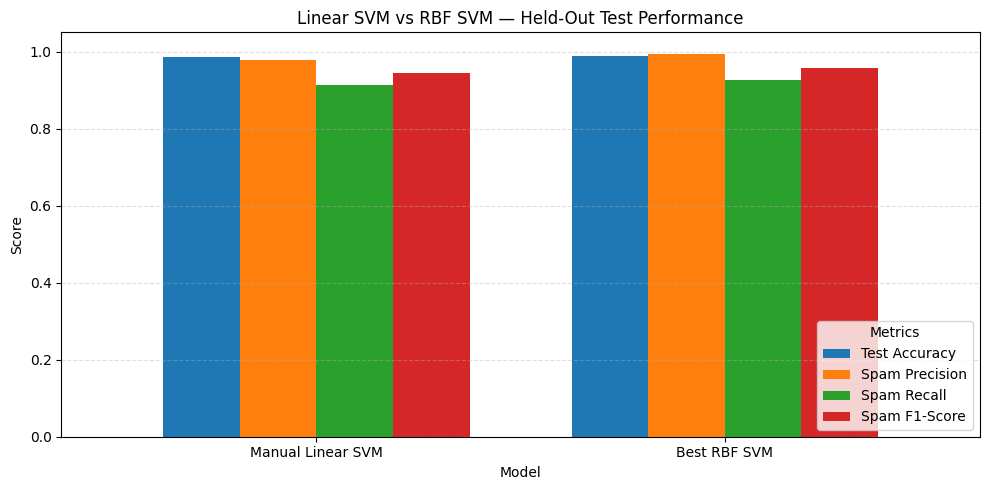

In [50]:

metrics = [
    "Test Accuracy",
    "Spam Precision",
    "Spam Recall",
    "Spam F1-Score"
]

ax = test_comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("Linear SVM vs RBF SVM — Held-Out Test Performance")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Metrics", loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

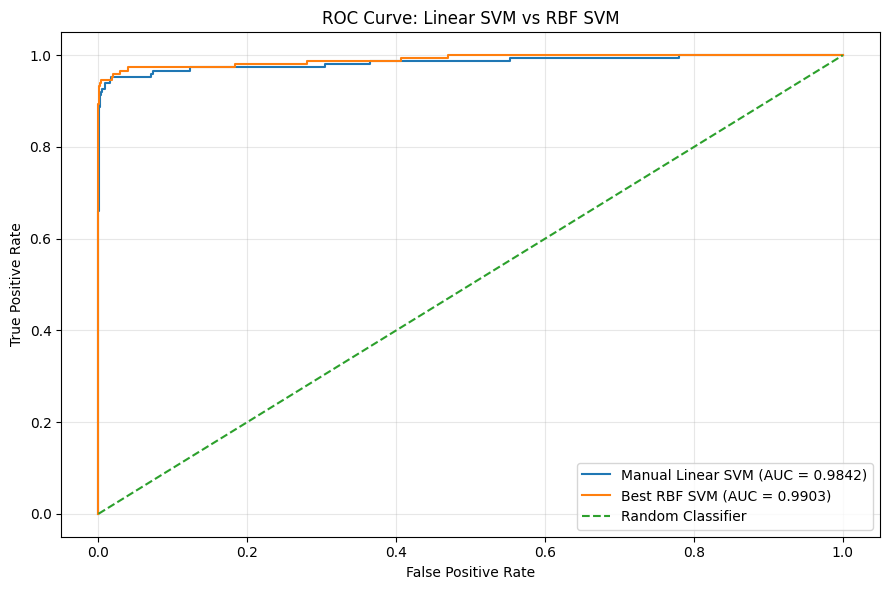

In [52]:


from sklearn.metrics import roc_curve, roc_auc_score

test_models = {
    "Manual Linear SVM": best_model,
    "Best RBF SVM": rbf_model
}

plt.figure(figsize=(9, 6))

auc_results = []

for model_name, model in test_models.items():
    y_test_scores = model.decision_function(X_test_tfidf)

    fpr, tpr, thresholds = roc_curve(
        y_test_svm,
        y_test_scores,
        pos_label=1
    )

    auc_value = roc_auc_score(
        y_test_svm,
        y_test_scores
    )

    auc_results.append({
        "Model": model_name,
        "Test AUC": auc_value
    })

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Linear SVM vs RBF SVM")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:

auc_df = pd.DataFrame(auc_results)

print("Held-Out Test AUC Comparison:")
print(auc_df.round(4).to_string(index=False))

Held-Out Test AUC Comparison:
            Model  Test AUC
Manual Linear SVM    0.9842
     Best RBF SVM    0.9903


In [54]:
import time

models = {
    "Manual Linear SVM": best_model,
    "Best RBF SVM": rbf_model
}

speed_results = []

for model_name, model in models.items():
    start_time = time.perf_counter()
    predictions = model.predict(X_test_tfidf)
    elapsed_time = time.perf_counter() - start_time

    speed_results.append({
        "Model": model_name,
        "Test Messages": X_test_tfidf.shape[0],
        "Prediction Time (seconds)": elapsed_time,
        "Time per Message (ms)": (
            elapsed_time / X_test_tfidf.shape[0]
        ) * 1000
    })

speed_df = pd.DataFrame(speed_results)
print(speed_df.round(5).to_string(index=False))

            Model  Test Messages  Prediction Time (seconds)  Time per Message (ms)
Manual Linear SVM           1115                    0.00029                0.00026
     Best RBF SVM           1115                    0.09084                0.08147


Manual Linear SVM is recommended for production because it provides strong classification performance while being faster and easier to interpret than RBF SVM.
High accuracy: Achieved 98.57% test accuracy.
Fast predictions: Classified 1,115 test messages in approximately 0.00029 seconds in your benchmark.
Low computational cost: Uses a simple weighted sum instead of calculating similarities with support vectors.
Interpretability: Learned feature weights help identify which words influence spam predictions.
Scalability: Its efficient predictions make it suitable for processing large volumes of SMS messages.